# 01 · Preprocessing — Steele 2020 PDAC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed,
remove detached islands, and split the manifold into its transcriptional compartments.
Pancreatic ductal adenocarcinoma (PDAC) is an epithelial malignancy; its malignant cells
span a dominant classical-ductal body and a minor stress/UPR state. Whether the
gastrulation / somitogenesis / neural-crest developmental axis is confined to one lobe
(Kürten 2021) or spans both (Bischoff / Sun / Lee 2021) is **derived in 02 from the
signature geography**, not assumed here, so both compartments are carried forward. Every
tunable choice is *derived from this dataset*, not inherited. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Steele2020_Pancreas | category: Pancreas


### Load malignant compartment
Steele et al. supply a per-cell `cell_type` annotation in which **Malignant** is an
explicit label (the publication's malignancy call, epithelial ductal-carcinoma cells);
the loader exposes it as `celltype`, so — unlike Zhou 2020, where malignancy was a
separate inferCNV column — the malignancy call here is `celltype == 'Malignant'`, taken
directly (per protocol: use the publication's calls).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Steele2020_Pancreas
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (48570, 32738)
malignant: (7874, 32738) | samples: 13
expression: X max 7.71 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per the protocol we first look for the largest **multiplicative** cliff in the sorted
per-sample counts (the natural separatrix between tumour-bearing samples and spillover).
Here the heuristic is **degenerate**: the largest ratio sits at the *top* of the
distribution (the single largest sample, 2091 vs 953), not at a low-count spillover
cliff, so cutting there would discard 12/13 samples. The clean-count-gap premise is
therefore **not met** for this dataset. We fall back to the protocol's ≥100-cell floor;
every sample clears it (min 117), so all 13 are retained — matching the same-tissue
Peng 2019 PDAC precedent (all samples kept).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
if gap == 0:
    print(f'gap is at the top of the distribution (degenerate) -> fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n.min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [2091  953  865  772  740  480  463  448  370  289  149  137  117]
largest multiplicative gap: 2091 -> 953 (ratio 2.19) at rank 0
gap is at the top of the distribution (degenerate) -> fall back to >= 100-cell floor
kept 13/13 samples (min per-sample = 117) -> 7874 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing):
we take the theta past which mixing plateaus. PDAC malignant cells are strongly
patient-specific (distinct CNVs / classical-basal balance), so the strongest theta is
chosen. PC count (20) and UMAP spread (1.3) follow the 10x precedents (Kürten / Sun /
Lee / Zhou, comparable cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2723 over-dispersed features (0:00:04) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2723
2026-07-31 20:10:42,341 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-31 20:10:44,720 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-31 20:10:44,794 - harmonypy - INFO - Iteration 1 of 30
2026-07-31 20:10:47,596 - harmonypy - INFO - Iteration 2 of 30
2026-07-31 20:10:50,380 - harmonypy - INFO - Iteration 3 of 30
2026-07-31 20:10:53,139 - harmonypy - INFO - Iteration 4 of 30
2026-07-31 20:10:55,703 - harmonypy - INFO - Iteration 5 of 30
2026-07-31 20:10:58,313 - harmonypy - INFO - Iteration 6 of 30
2026-07-31 20:11:00,446 - harmonypy - INFO - Iteration 7 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop
any cell outside the main connected component — stripping physically detached specks
while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 0 cells in 0 detached islands


### Compartment split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. Unlike Zhou 2020 — where
the lobes split by **cell cycle** — PDAC here is almost entirely non-cycling (~6% cycling
overall), so the split is transcriptional, not proliferative. We label the lobes *by
biology* from their top differential markers and Moffitt classical/basal scores: the
dominant lobe is **Ductal-classical** (MUC1 / FXYD3 / KRT8 / LGALS3BP, high classical
score); the minor lobe is a **Stress/UPR** state (DDIT3/CHOP, PPP1R15A/GADD34, DNAJB9,
MAFF). Basal-like scores are ~0 in both, consistent with the classical-predominant Steele
cohort. Whether the trajectory is scoped to one lobe or spans both is decided in 02 from
the signature geography, not assumed here; both are carried forward.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.groupby_cyc if False else
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
# Moffitt classical / basal signatures (Moffitt et al. 2015)
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2',
             'CLRN3','LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B',
         'LY6D','SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
# marker-based labelling: higher classical score = Ductal-classical; other = Stress/UPR
cl = adata.obs.groupby('lobe', observed=True)['classical_score'].mean()
duct_lobe = cl.idxmax()
lab_map = {l: ('Ductal-classical' if l==duct_lobe else 'Stress/UPR')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 6782, '1': 1092}
overall cycling fraction: 0.050
cycling fraction per lobe: {'0': 0.057, '1': 0.007}
classical: 17/17 genes | per-lobe mean {'0': 0.397, '1': 0.236}
basal: 19/19 genes | per-lobe mean {'0': 0.013, '1': 0.001}
compartments: {'Ductal-classical': 6782, 'Stress/UPR': 1092}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory
panels are shown after a single **rigid rotation** to the house horizontal layout
(distance-preserving — *not* a re-embedding). The orientation is derived **once here**,
stored as `X_umap_lin`, and re-used unchanged by 02/03/04 so every deliverable UMAP shares
one orientation (binding). Two ingredients: (i) the rotation angle = the manifold's **axis
of maximal variance**; (ii) the sign puts the **developmental origin on the left** so
pseudotime runs left→right once fit in 02. Zhou 2020 set that sign from the *cycling* pole
(there the somitogenesis-high root lobe was the more proliferative one); **that proxy is
invalid here** — PDAC is ~94% non-cycling and cell cycle is orthogonal to the
developmental axis (shown in 02, |rho|≤0.08). So the sign is set directly from the
developmental-module geography: the **posterior-somitogenesis-high / neural-crest-low**
pole (the origin) is placed on the left. The three modules are scored here against the
shared union pool solely to orient the layout; 02 re-scores them canonically for the
trajectory.

In [8]:
# score developmental modules (for orientation sign only; 02 re-scores canonically)
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]     # pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.02
house orientation: rigid rotation +133.3deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is
made on the regenerated embedding itself plus a per-neighbourhood metric (iLISI across the
theta sweep), not a scalar alone; the deliverable `samples.pdf` follows.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal);')
print('both compartments contain multiple samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 5.15 of 13 samples
13 samples share one continuous manifold (one connected component after island removal);
both compartments contain multiple samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the
manifold is h5ad-serializable; analysis-relevant columns are preserved.

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7874, 23553)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 7874


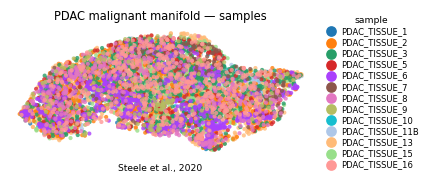

In [11]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every other panel.
# Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence,
# shown on the house orientation (X_umap_lin) so this panel shares one orientation with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Steele et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])